# Correlated assets and basket references

Exact terminal GBM simulation with unequal asset inputs and both positive and negative pair correlations. The first experiments check the joint state distribution before using it for basket-option references. All simulated states and moment diagnostics come from `bsde_pricing`; cells organise the experiments and plots.

The model uses constant parameters under the risk-neutral measure, continuous dividend yields and a positive-definite Brownian correlation matrix. Rates are continuously compounded and time is measured in years. There is no time-discretisation error in these terminal samples. Sampling error and floating-point error remain.

In [1]:
from pathlib import Path
from itertools import combinations
import html
import os
import platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import HTML, display

cwd = Path.cwd()
root = next((p for p in (cwd, cwd.parent) if (p / "bsde_pricing").is_dir()), None)
if root is None:
    raise RuntimeError("Open the deep-bsde-pricing repository folder and restart the kernel.")
os.chdir(root)
from bsde_pricing.problems import GBMModel, EuropeanCall, PricingCase, correlated_case
from bsde_pricing.sampling import TerminalSampleDiagnostics

%matplotlib inline
plt.rcParams.update({"figure.dpi":90, "axes.spines.top":False,
                     "axes.spines.right":False, "axes.grid":True, "grid.alpha":0.2})

def table(headers, rows):
    head = "".join(f"<th>{html.escape(str(v))}</th>" for v in headers)
    body = "".join("<tr>" + "".join(
        f"<td>{html.escape(format(v, '.7g') if isinstance(v, (float, np.floating)) else str(v))}</td>"
        for v in row) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))

table(["Execution", "Version"], [("Python", platform.python_version()),
      ("NumPy", np.__version__), ("Matplotlib", matplotlib.__version__)])

Execution,Version
Python,3.12.16
NumPy,2.5.4
Matplotlib,3.11.2


## 1. Inputs and Cholesky orientation

For $\rho=LL^\top$ and independent standard normals $z$, the correlated column vector is $y=Lz$. Path samples are stored as rows, so the array operation is `Z @ L.T`. The exact state is

$$S_i(T)=S_i(0)\exp\left((r-q_i-\tfrac12\sigma_i^2)\tau+\sigma_i\sqrt\tau\,y_i\right).$$

Each output has shape `(number of paths, number of assets)`. Asset columns retain the order of spots, volatilities, dividends and correlation rows. The correlation matrix must be symmetric, have unit diagonal and be positive definite. Perfectly correlated singular cases are outside the present sampler contract.

The default is deliberately asymmetric: three spots, volatilities and dividend yields, with correlations 0.6, -0.2 and 0.3. The associated arithmetic-call weights define a future pricing problem; no option price is claimed in these distribution checks. Edit inputs and run all cells from a fresh kernel. The visual diagnostics require at least two assets, positive volatility in each coordinate and a positive horizon.

In [2]:
case = correlated_case()
horizon = 1.0
n_paths = 100_000
seed = 2026

model = case.model
initial_spots = case.initial_spots
if model.dimension < 2 or min(model.volatilities) <= 0 or horizon <= 0:
    raise ValueError("These plots require at least two assets, positive volatilities and horizon.")
labels = [f"Asset {i+1}" for i in range(model.dimension)]
rho = np.array(model.correlation)
factor = np.linalg.cholesky(rho)
table(["Asset", "Initial spot", "Volatility", "Dividend yield", "Weight"],
      list(zip(labels, initial_spots, model.volatilities, model.dividend_yields, case.contract.weights)))
table(["Setting", "Value"], [("Rate", model.rate), ("Horizon", horizon),
      ("Paths", n_paths), ("Seed", seed), ("Generator", "PCG64"),
      ("Smallest correlation eigenvalue", np.linalg.eigvalsh(rho).min()),
      ("Max absolute factor reconstruction error", np.max(np.abs(factor @ factor.T - rho)))])
table(["Correlation", *labels], [(label, *row) for label, row in zip(labels, rho)])
terminal = model.sample_terminal(initial_spots, horizon, n_paths, np.random.default_rng(seed))
report = TerminalSampleDiagnostics.from_sample(model, initial_spots, horizon, terminal)
log_returns = np.log(terminal) - np.log(initial_spots)

Asset,Initial spot,Volatility,Dividend yield,Weight
Asset 1,80,0.15,0,0.2
Asset 2,100,0.25,0.01,0.3
Asset 3,120,0.35,0.02,0.5


Setting,Value
Rate,0.03
Horizon,1
Paths,100000
Seed,2026
Generator,PCG64
Smallest correlation eigenvalue,0.2356701
Max absolute factor reconstruction error,5.551115e-17


Correlation,Asset 1,Asset 2,Asset 3
Asset 1,1,0.6,-0.2
Asset 2,0.6,1,0.3
Asset 3,-0.2,0.3,1


## 2. Marginal means and uncertainty

The log return $X_i=\log(S_i(T)/S_i(0))$ has mean $(r-q_i-\sigma_i^2/2)\tau$ and variance $\sigma_i^2\tau$. Its sample-mean standard error is $\sigma_i\sqrt{\tau/N}$. The terminal price mean is $S_i(0)e^{(r-q_i)\tau}$, with lognormal variance used for its standard error.

Bars below are pointwise normal-approximation intervals around observed means, using theoretical standard errors. They are distribution diagnostics, not basket-option confidence intervals or simultaneous acceptance bands. A log-return mean can be negative while the terminal price mean exceeds its initial spot, because exponentiation is nonlinear.

Asset,Expected log mean,Observed log mean,Log mean SE,Error / SE,Expected terminal mean,Observed terminal mean
Asset 1,0.01875,0.01851113,0.0004743416,-0.5035752,82.43636,82.41818
Asset 2,-0.01125,-0.01013352,0.0007905694,1.412245,102.0201,102.1455
Asset 3,-0.05125,-0.04985481,0.001106797,1.260567,121.206,121.3305


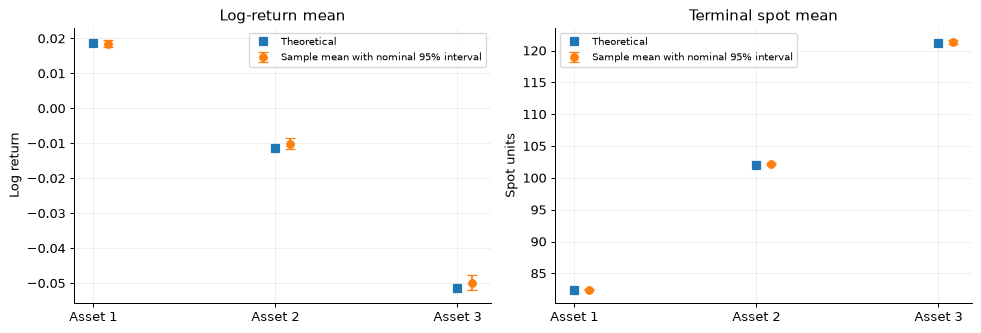

In [3]:
mean_expected = np.array(report.log_return_mean_expected)
mean_observed = np.array(report.log_return_mean_observed)
mean_se = np.array(report.log_return_mean_standard_error)
terminal_expected = np.array(report.terminal_mean_expected)
terminal_observed = np.array(report.terminal_mean_observed)
terminal_se = np.array(report.terminal_mean_standard_error)
table(["Asset", "Expected log mean", "Observed log mean", "Log mean SE", "Error / SE", "Expected terminal mean", "Observed terminal mean"],
      [(labels[i], mean_expected[i], mean_observed[i], mean_se[i],
        (mean_observed[i] - mean_expected[i]) / mean_se[i], terminal_expected[i], terminal_observed[i])
       for i in range(model.dimension)])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, expected, observed, se, title in (
    (axes[0], mean_expected, mean_observed, mean_se, "Log-return mean"),
    (axes[1], terminal_expected, terminal_observed, terminal_se, "Terminal spot mean"),
):
    x = np.arange(model.dimension)
    ax.plot(x, expected, "s", label="Theoretical")
    ax.errorbar(x + 0.08, observed, yerr=1.95996398454 * se, fmt="o", capsize=4,
                label="Sample mean with nominal 95% interval")
    ax.set_xticks(x, labels)
    ax.set(title=title, ylabel="Log return" if ax is axes[0] else "Spot units")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 3. Joint covariance and correlation

The theoretical log-return covariance is $\Sigma_{ij}=\sigma_i\sigma_j\rho_{ij}\tau$. For unbiased Gaussian sample covariance $\widehat\Sigma$,

$$\operatorname{SE}(\widehat\Sigma_{ij})=\sqrt{\frac{\Sigma_{ii}\Sigma_{jj}+\Sigma_{ij}^2}{N-1}}.$$

The formula supplies a scale for the observed discrepancy. Matrix entries are dependent and a heatmap is not a simultaneous confidence test. Correlation of positive-volatility log returns equals the Brownian input correlation; Pearson correlation of terminal price levels generally does not. The last two columns of the table distinguish them.

Pair,Expected log covariance,Observed log covariance,Covariance SE,Error / SE,Input correlation,Observed log correlation,Observed level correlation
"1, 2",0.0225,0.02252538,0.0001382939,0.1835031,0.6,0.5994468,0.5941927
"1, 3",-0.0105,-0.01038751,0.0001693083,0.6644354,-0.2,-0.1983199,-0.1903263
"2, 3",0.02625,0.02646786,0.000288884,0.7541501,0.3,0.3030453,0.2931606


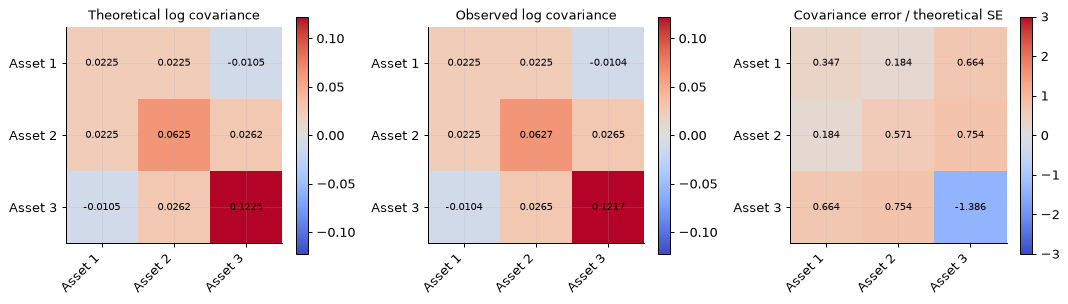

In [4]:
cov_expected = np.array(report.log_return_covariance_expected)
cov_observed = np.array(report.log_return_covariance_observed)
cov_se = np.array(report.log_return_covariance_standard_error)
cov_z = (cov_observed - cov_expected) / cov_se
log_correlation = np.corrcoef(log_returns, rowvar=False)
level_correlation = np.corrcoef(terminal, rowvar=False)
pairs = list(combinations(range(model.dimension), 2))
table(["Pair", "Expected log covariance", "Observed log covariance", "Covariance SE", "Error / SE", "Input correlation", "Observed log correlation", "Observed level correlation"],
      [(f"{i+1}, {j+1}", cov_expected[i,j], cov_observed[i,j], cov_se[i,j], cov_z[i,j],
        rho[i,j], log_correlation[i,j], level_correlation[i,j]) for i,j in pairs])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
limit = max(np.abs(cov_expected).max(), np.abs(cov_observed).max())
for ax, values, title, bound in zip(axes, (cov_expected, cov_observed, cov_z),
        ("Theoretical log covariance", "Observed log covariance", "Covariance error / theoretical SE"),
        (limit, limit, max(3.0, np.abs(cov_z).max()))):
    im = ax.imshow(values, vmin=-bound, vmax=bound, cmap="coolwarm")
    ax.set_xticks(range(model.dimension), labels, rotation=45, ha="right")
    ax.set_yticks(range(model.dimension), labels)
    ax.set_title(title, fontsize=10)
    for i in range(model.dimension):
        for j in range(model.dimension):
            ax.text(j, i, format(values[i,j], ".3f" if ax is axes[2] else ".4f"), ha="center", va="center", fontsize=8)
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
plt.show()

## 4. Dependence in individual samples

Standardisation uses the theoretical mean and standard deviation. Each coordinate then has a standard normal marginal, while the joint cloud retains the input correlation. The plot shows only the first 3,000 paths for readability; correlations in the titles use the full sample. For models with more than three assets, only the first three pairs are displayed.

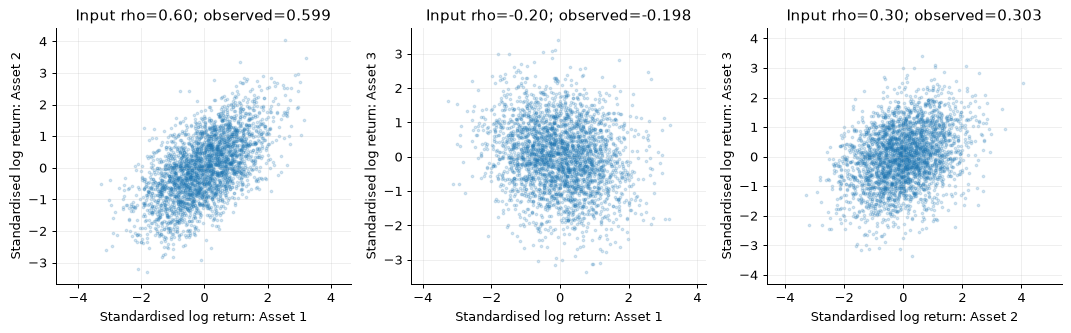

In [5]:
standardised = (log_returns - mean_expected) / np.sqrt(np.diag(cov_expected))
shown_pairs = pairs[:3]
fig, axes = plt.subplots(1, len(shown_pairs), figsize=(4 * len(shown_pairs), 3.8), squeeze=False)
for ax, (i,j) in zip(axes[0], shown_pairs):
    ax.scatter(standardised[:3000,i], standardised[:3000,j], s=4, alpha=0.18)
    ax.set(xlabel=f"Standardised log return: {labels[i]}",
           ylabel=f"Standardised log return: {labels[j]}",
           title=f"Input rho={rho[i,j]:.2f}; observed={log_correlation[i,j]:.3f}")
    ax.set_aspect("equal", adjustable="datalim")
fig.tight_layout()
plt.show()

## 5. Change dependence while holding marginals fixed

This two-asset experiment uses the first two assets' inputs and changes only their correlation. Both marginal distributions remain the same in law. Their finite-sample means need not be identical when the Cholesky transform changes. Seeds are matched across configurations, making the experiment reproducible and inducing dependence between the estimates.

The scatter plots use 3,000 paths; the table uses all paths and the shared diagnostic implementation. Correlation magnitudes strictly below one keep each matrix positive definite. No basket-option price or delta is inferred from these distribution checks.

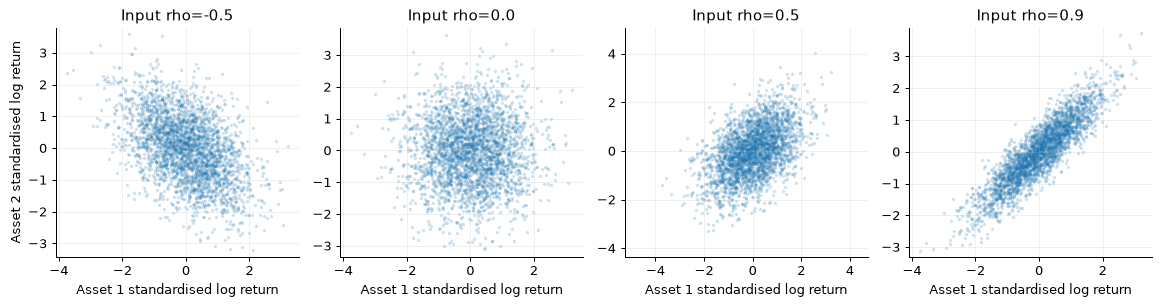

Input rho,Observed log rho,Expected cross-covariance,Observed cross-covariance,Observed terminal mean 1,Observed terminal mean 2
-0.5,-0.5012916,-0.01875,-0.01876192,82.40732,102.1391
0,-0.001298393,0,-4.855327e-05,82.40732,102.1195
0.5,0.4996065,0.01875,0.01867782,82.40732,102.0758
0.9,0.9000976,0.03375,0.0336746,82.40732,102.0101


In [6]:
correlation_values = (-0.5, 0.0, 0.5, 0.9)
sweep_rows = []
fig, axes = plt.subplots(1, 4, figsize=(13, 3.5))
for ax, value in zip(axes, correlation_values):
    pair_model = GBMModel(model.rate, model.volatilities[:2], model.dividend_yields[:2],
                          ((1.0, value), (value, 1.0)))
    pair_terminal = pair_model.sample_terminal(initial_spots[:2], horizon, n_paths,
                                               np.random.default_rng(seed))
    pair_report = TerminalSampleDiagnostics.from_sample(pair_model, initial_spots[:2], horizon, pair_terminal)
    pair_logs = np.log(pair_terminal) - np.log(initial_spots[:2])
    observed_rho = np.corrcoef(pair_logs, rowvar=False)[0,1]
    sweep_rows.append((value, observed_rho, pair_report.log_return_covariance_expected[0][1],
                       pair_report.log_return_covariance_observed[0][1],
                       *pair_report.terminal_mean_observed))
    standard = (pair_logs - pair_report.log_return_mean_expected) / (
        np.array(pair_model.volatilities) * np.sqrt(horizon))
    ax.scatter(standard[:3000,0], standard[:3000,1], s=3, alpha=0.15)
    ax.set(xlabel="Asset 1 standardised log return", title=f"Input rho={value:.1f}")
    ax.set_aspect("equal", adjustable="datalim")
axes[0].set_ylabel("Asset 2 standardised log return")
fig.tight_layout()
plt.show()
table(["Input rho", "Observed log rho", "Expected cross-covariance", "Observed cross-covariance", "Observed terminal mean 1", "Observed terminal mean 2"], sweep_rows)

## Interpretation and scope

- Correlation changes the joint distribution while leaving each asset's theoretical marginal distribution unchanged.
- Unequal volatilities scale covariance: correlation and covariance have different units and values.
- Scalar seeded transitions retain their previous calculation order. Zero horizon and all-zero volatility consume no random draws; mixed zero-volatility models draw a full normal vector and then apply each coordinate's volatility.
- The current samples are terminal states. They provide no intervening path grid for hedging or BSDE time stepping.
- Positive-definite correlation is required; singular matrices are rejected, and no nearest-correlation repair is performed.
- These results validate the state sampler. Closed-form geometric-basket prices and coordinate deltas are the next reference calculation. Arithmetic-basket pricing and strong Monte Carlo references require their own checks.

Detailed formulas and implementation contracts are in the [methodology](../docs/methodology.md#correlated-terminal-gbm).